# **target**
# ****الهدف:** التنبؤ بصلاحية المياه للشرب (`Potability`: 1 = صالحة، 0 = غير صالحة).


# **(col 1) ph: نسبة الحموضة/القلوية (من 0 إلى 14).
# (حسب WHO) النسبة الآمنة عالمياً تتراوح بين 6.5 و 8.5

# **(col2) Hardness: (تركيز أملاح الكالسيوم والمغنيسيوم) يقاس بـ عسر الماء  mg/L

# **(col 3) Solids: إجمالي المواد الصلبة الذائبة (TDS) يقاس بـ **
# **ppm. الحد المرغوب فيه < 500 mg/L والأقصى 1000 mg/L.**

#(col 4) Chloramines: كمية الكلورامين المستخدمة للتطهير بـ ppm
## **(الحد الآمن حتى 4 mg/L).**

# **(col 5). Sulfate (الكبريتات)الوصف: كمية الأملاح الكبريتية الذائبة في المياه والموجودة بشكل طبيعي في الصخور والتربة.وحدة القياس mg/L**

# **(col 6 ). Conductivity (التوصيل الكهربائي)الوصف: قياس قدرة الماء على توصيل التيار الكهربائي (مؤشر لتركيز الأيونات والملاحة).وحدة القياسS/cmالمعيار الدولي (WHO): يفضل ألا يتجاوز 400 S/cm**

# **(col 7). Organic_carbon (الكربون العضوي الكلي - TOC)الوصف: مقياس لكيمياء المواد العضوية الكلية في مصدر المياه.وحدة القياسppm**

# **(col 8)Trihalomethanes: نواتج تفاعل الكلور مع المواد العضوية (THMs) بـ μg/L (الحد الآمن حتى 80 ppm/μg/L)**

# **(col 9)Turbidity: العكارة (قياس مدى نفاذية الضوء وجودة المواد العالقة) بـ NTU (الحد الموصى به أقل من 5 NTU).**

In [47]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

import warnings
warnings.filterwarnings('ignore')

In [48]:
RANDOM_STATE = 42
sns.set_theme(style='whitegrid')

In [49]:
df = pd.read_csv('/content/water_potability.csv')

# **EDA**

In [50]:
display(df.head())

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


In [51]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               2785 non-null   float64
 1   Hardness         3276 non-null   float64
 2   Solids           3276 non-null   float64
 3   Chloramines      3276 non-null   float64
 4   Sulfate          2495 non-null   float64
 5   Conductivity     3276 non-null   float64
 6   Organic_carbon   3276 non-null   float64
 7   Trihalomethanes  3114 non-null   float64
 8   Turbidity        3276 non-null   float64
 9   Potability       3276 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 256.1 KB


In [52]:
print('Shape:', df.shape, '| Duplicates:', df.duplicated().sum())

Shape: (3276, 10) | Duplicates: 0


In [53]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
ph,2785.0,7.080795,1.594320,0.000000,6.093092,7.036752,8.062066,14.000000
Hardness,3276.0,196.369496,32.879761,47.432000,176.850538,196.967627,216.667456,323.124000
Solids,3276.0,22014.092526,8768.570828,320.942611,15666.690297,20927.833607,27332.762127,61227.196008
Chloramines,3276.0,7.122277,1.583085,0.352000,6.127421,7.130299,8.114887,13.127000
Sulfate,2495.0,333.775777,41.416840,129.000000,307.699498,333.073546,359.950170,481.030642
Conductivity,3276.0,426.205111,80.824064,181.483754,365.734414,421.884968,481.792304,753.342620
Organic_carbon,3276.0,14.284970,3.308162,2.200000,12.065801,14.218338,16.557652,28.300000
Trihalomethanes,3114.0,66.396293,16.175008,0.738000,55.844536,66.622485,77.337473,124.000000
Turbidity,3276.0,3.966786,0.780382,1.450000,3.439711,3.955028,4.500320,6.739000
Potability,3276.0,0.390110,0.487849,0.000000,0.000000,0.000000,1.000000,1.000000


In [54]:
missing = df.isna().sum().to_frame('missing')

In [55]:
missing['%'] = (missing['missing'] / len(df) * 100).round(1)
display(missing[missing['missing'] > 0])

,missing,%
ph,491,15.0
Sulfate,781,23.8
Trihalomethanes,162,4.9


In [56]:
class_share = df['Potability'].value_counts(normalize=True).round(3)

In [57]:
print('Class share:\n', class_share)

Class share:
 Potability
0    0.61
1    0.39
Name: proportion, dtype: float64


In [58]:
print(f"\n Balanced accuracy (توقع الفئة الأكبر): {class_share.max():.2f}")


 Balanced accuracy (توقع الفئة الأكبر): 0.61


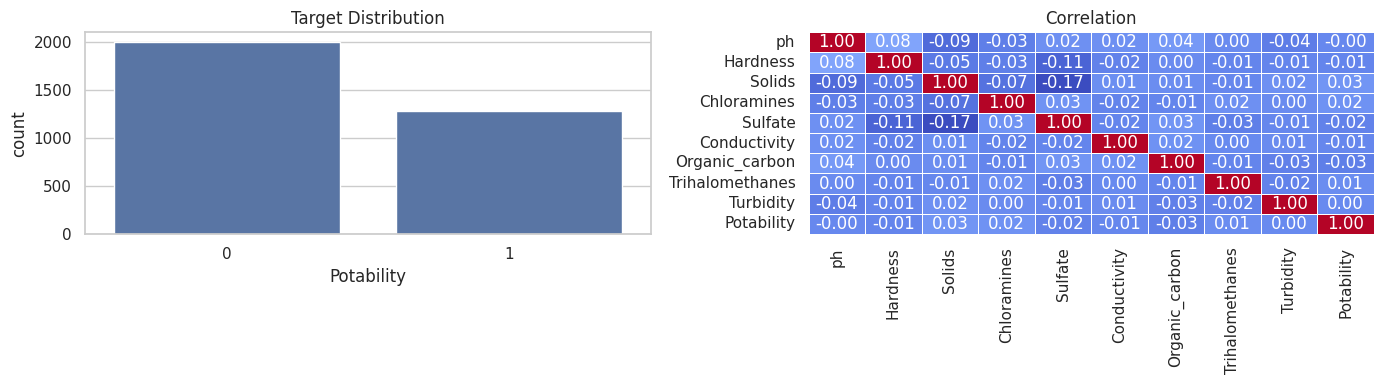

In [59]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.countplot(data=df, x='Potability', ax=axes[0]).set_title('Target Distribution')
corr = df.corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', linewidths=.5, ax=axes[1], cbar=False)
axes[1].set_title('Correlation')
plt.tight_layout()
plt.show()

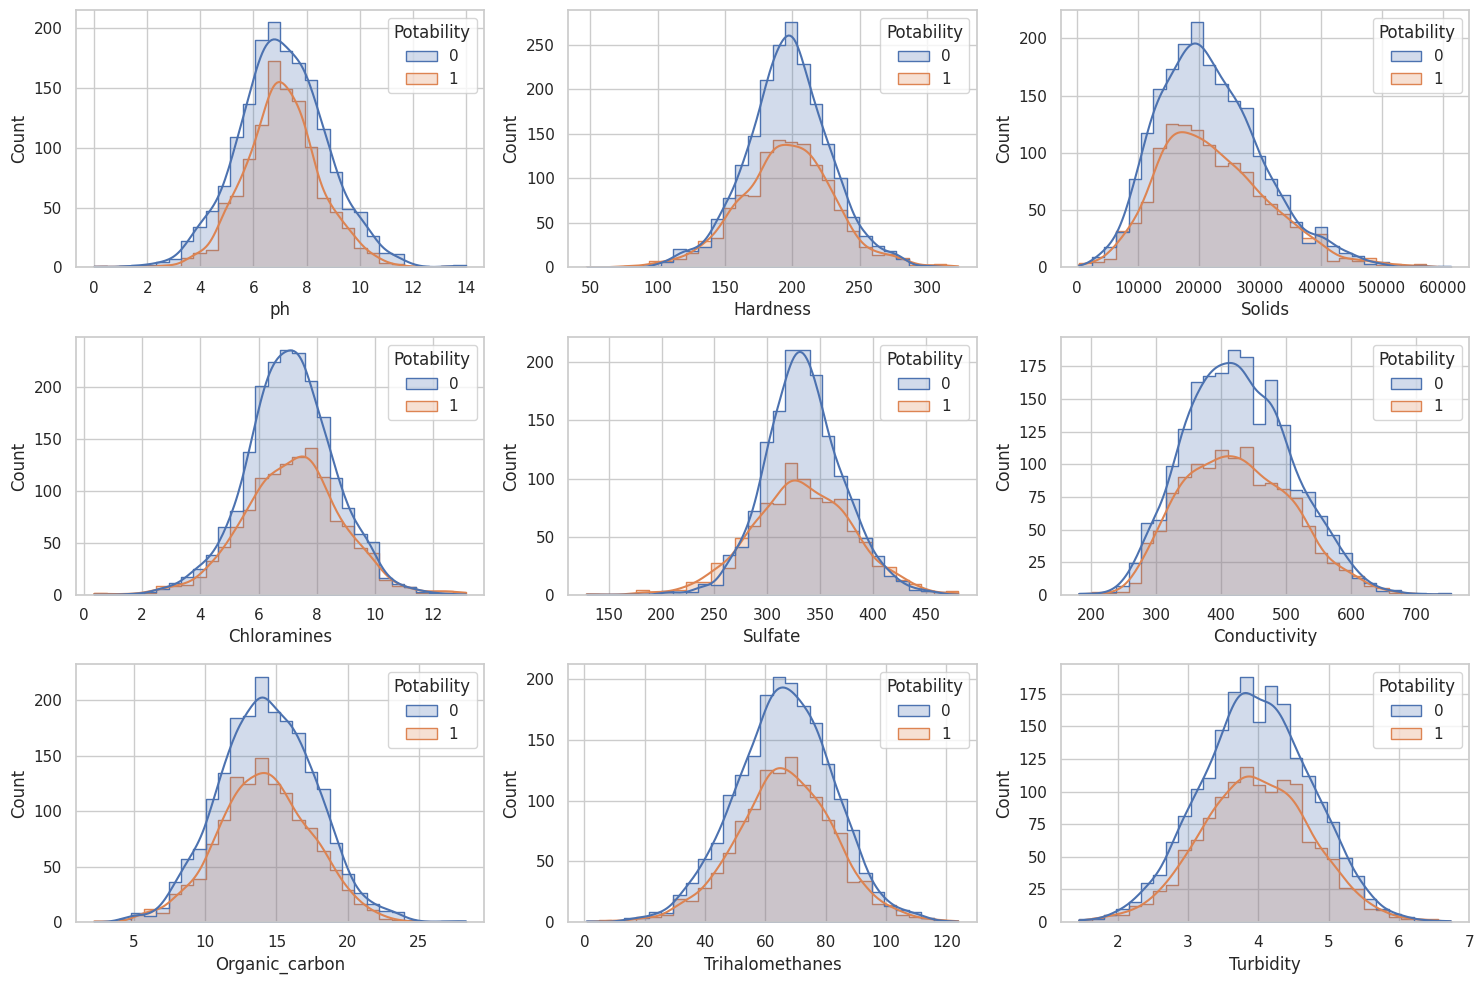

In [60]:
features = df.columns.drop('Potability')
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for ax, col in zip(axes.ravel(), features):
    sns.histplot(data=df, x=col, hue='Potability', kde=True, bins=30, ax=ax, element='step')
plt.tight_layout()
plt.show()

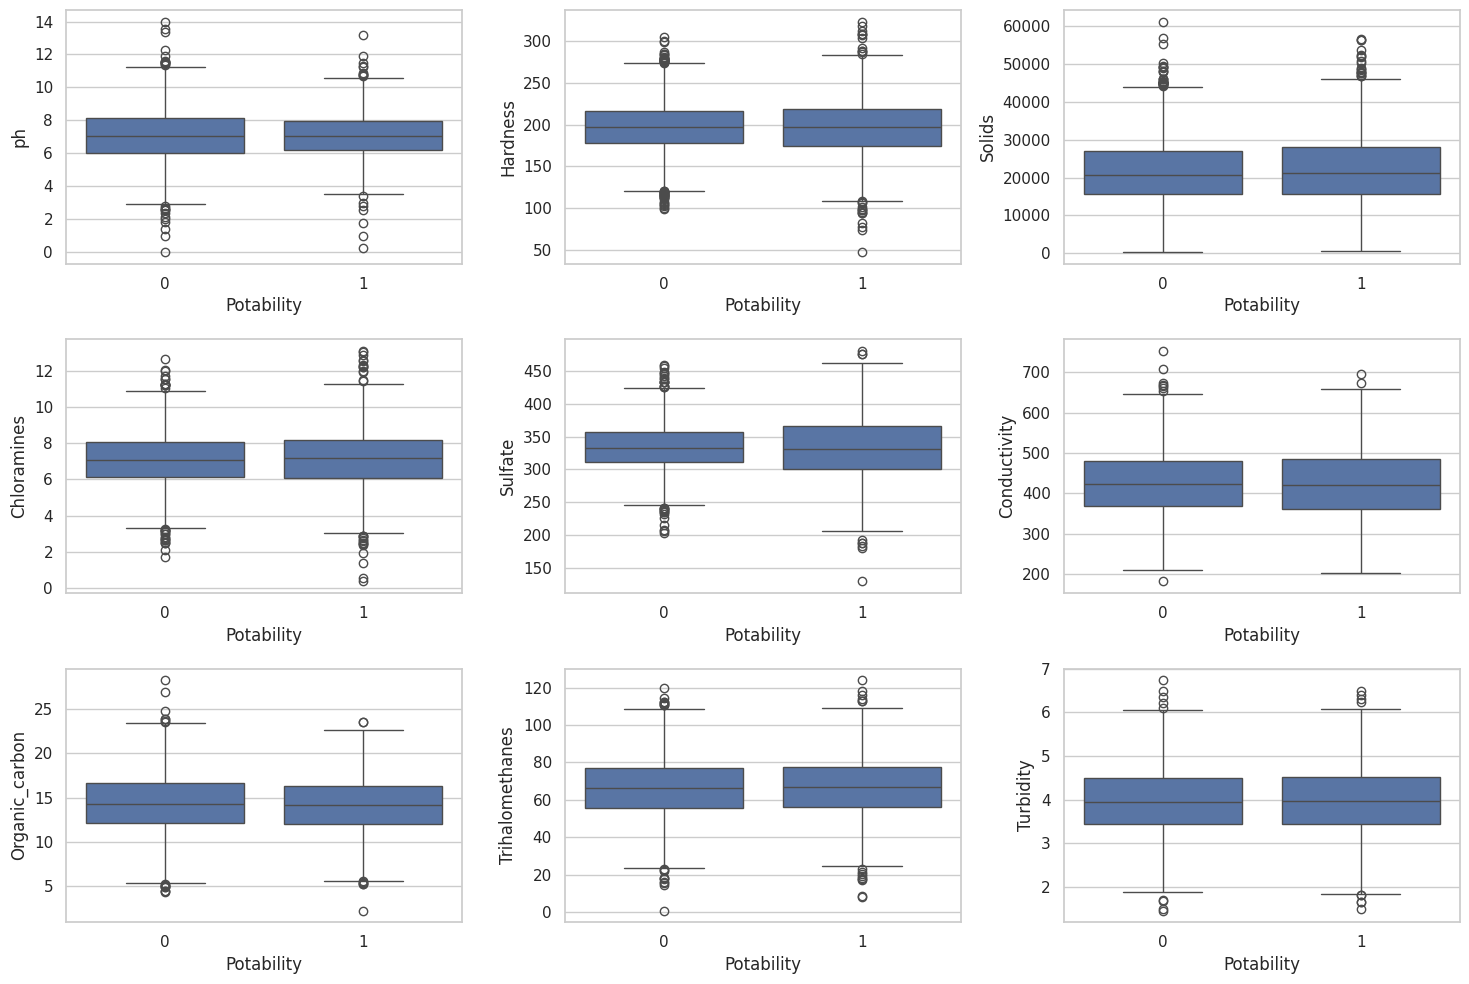

In [61]:
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for ax, col in zip(axes.ravel(), features):
    sns.boxplot(data=df, x='Potability', y=col, ax=ax)
plt.tight_layout(); plt.show()

# **الارتباط بين أي عمود والتارجت ضعيف جداً (أقل من 0.05) **
# **الـ outliers طبيعية في قياسات المياه فمش هنمسحها**

# Data Split

In [73]:
x = df.drop('Potability', axis=1)
y = df['Potability']

In [74]:
from sklearn.model_selection import train_test_split

In [75]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

In [76]:
from sklearn.model_selection import StratifiedKFold

In [77]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print(x_train.shape, x_test.shape)

(2620, 9) (656, 9)


In [78]:
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE

def make_pipe(model):
    return ImbPipeline([
        ('imputer', KNNImputer(n_neighbors=5)),
        ('scaler', StandardScaler()),
        ('model', model),
    ])

In [79]:
!pip install -q imbalanced-learn xgboost lightgbm catboost

In [80]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.experimental import enable_hist_gradient_boosting
from sklearn.ensemble import HistGradientBoostingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.model_selection import cross_validate

In [81]:
base_models = {
    'Logistic Regression': LogisticRegression(max_iter=2000),
    'KNN': KNeighborsClassifier(n_neighbors=15),
    'SVC': SVC(probability=True, random_state=RANDOM_STATE),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE),
    'Naive Bayes': GaussianNB(),
    'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1),
    'Extra Trees': ExtraTreesClassifier(n_estimators=300, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1),
    'AdaBoost': AdaBoostClassifier(n_estimators=100, learning_rate=0.5, random_state=RANDOM_STATE),
    'Gradient Boosting': GradientBoostingClassifier(max_depth=3, learning_rate=0.05, n_estimators=150, random_state=RANDOM_STATE),
    'Hist Gradient Boosting': HistGradientBoostingClassifier(learning_rate=0.03, max_iter=200, max_depth=4, random_state=RANDOM_STATE),
    'XGBoost': XGBClassifier(n_estimators=150, max_depth=3, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, random_state=RANDOM_STATE),
    'LightGBM': LGBMClassifier(n_estimators=150, learning_rate=0.05, num_leaves=15, random_state=RANDOM_STATE, verbose=-1),
    'CatBoost': CatBoostClassifier(iterations=300, depth=5, learning_rate=0.05, verbose=0, random_state=RANDOM_STATE),
}


rows = {}
for name, m in base_models.items():
    cv = cross_validate(make_pipe(m), x_train, y_train, cv=skf,
                        scoring=['accuracy', 'balanced_accuracy', 'roc_auc'])
    rows[name] = {'CV Accuracy': cv['test_accuracy'].mean(),
                  'CV Balanced Acc': cv['test_balanced_accuracy'].mean(),
                  'CV ROC-AUC': cv['test_roc_auc'].mean()}

cv_table = pd.DataFrame(rows).T.sort_values('CV Accuracy', ascending=False).round(4)
cv_table

,CV Accuracy,CV Balanced Acc,CV ROC-AUC
SVC,0.6729,0.6061,0.6955
Random Forest,0.6695,0.6109,0.6838
Extra Trees,0.6691,0.5947,0.6950
CatBoost,0.6599,0.6020,0.6875
Hist Gradient Boosting,0.6519,0.5826,0.6529
LightGBM,0.6519,0.5914,0.6627
XGBoost,0.6447,0.5733,0.6494
Gradient Boosting,0.6420,0.5644,0.6356
KNN,0.6374,0.5740,0.6462
Naive Bayes,0.6237,0.5525,0.5844


In [82]:
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import RandomizedSearchCV

In [83]:
search_spaces = {
    'SVC': (
        SVC(probability=True, random_state=RANDOM_STATE),
        {'model__C': loguniform(0.3, 50), 'model__gamma': loguniform(0.01, 1)}, 30),
    'Extra Trees': (
        ExtraTreesClassifier(n_estimators=400, random_state=RANDOM_STATE, n_jobs=-1),
        {'model__max_depth': [None, 12, 20, 30], 'model__min_samples_leaf': randint(1, 6),
         'model__max_features': ['sqrt', 'log2', 0.5]}, 20),
    'Random Forest': (
        RandomForestClassifier(n_estimators=400, random_state=RANDOM_STATE, n_jobs=-1),
        {'model__max_depth': [None, 8, 12, 16, 24], 'model__min_samples_leaf': randint(1, 8),
         'model__max_features': ['sqrt', 'log2', 0.5]}, 20),
    'XGBoost': (
        XGBClassifier(random_state=RANDOM_STATE),
        {'model__n_estimators': randint(100, 500), 'model__learning_rate': loguniform(0.01, 0.2),
         'model__max_depth': randint(2, 7), 'model__subsample': uniform(0.6, 0.4),
         'model__colsample_bytree': uniform(0.6, 0.4), 'model__min_child_weight': randint(1, 10)}, 30),
    'LightGBM': (
        LGBMClassifier(random_state=RANDOM_STATE, verbose=-1),
        {'model__n_estimators': randint(100, 500), 'model__learning_rate': loguniform(0.01, 0.2),
         'model__num_leaves': randint(4, 40), 'model__min_child_samples': randint(10, 60),
         'model__subsample': uniform(0.6, 0.4), 'model__colsample_bytree': uniform(0.6, 0.4)}, 30),
}

tuned = {}
for name, (model, grid, n_iter) in search_spaces.items():
    search = RandomizedSearchCV(make_pipe(model), grid, n_iter=n_iter, cv=skf, scoring='accuracy',
                                random_state=RANDOM_STATE, n_jobs=-1)
    search.fit(x_train, y_train)
    tuned[name] = search.best_estimator_
    print(f"{name:14s} CV accuracy = {search.best_score_:.4f}")

SVC            CV accuracy = 0.6775
Extra Trees    CV accuracy = 0.6740
Random Forest  CV accuracy = 0.6695
XGBoost        CV accuracy = 0.6565
LightGBM       CV accuracy = 0.6603


# **Ensembles: Voting & Stacking (على الموديلات المضبوطة)**
# **دمج أفضل النماذج المضبوطة معاً باستخدام VotingClassifier (Soft Voting) و StackingClassifier لتقليل الأخطاء الفردية ورفع استقرار التوقع.**

In [84]:
from sklearn.ensemble import VotingClassifier, StackingClassifier

In [85]:
estimators = [(n.replace(' ', '_'), m) for n, m in tuned.items()]

voting = VotingClassifier(estimators=estimators, voting='soft')
stacking = StackingClassifier(estimators=estimators, final_estimator=LogisticRegression(max_iter=2000),
                              cv=5, stack_method='predict_proba')

voting.fit(x_train, y_train)
stacking.fit(x_train, y_train)

final_models = {**tuned, 'Voting (soft)': voting, 'Stacking': stacking}

# **Final Evaluation على الـ Test Set**

# **اختبار النماذج نهائياً على بيانات الاختبار واستخراج   (Accuracy, Balanced Accuracy, F1, ROC-AUC) مع رسم الـ Confusion Matrix و ROC Curves.**

In [91]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, confusion_matrix, classification_report

In [88]:
def evaluate(model):
    pred = model.predict(x_test)
    prob = model.predict_proba(x_test)[:, 1]
    return {
        'Accuracy': accuracy_score(y_test, pred),
        'Balanced Acc': balanced_accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred),
        'F1': f1_score(y_test, pred),
        'ROC-AUC': roc_auc_score(y_test, prob),
    }

results = pd.DataFrame({n: evaluate(m) for n, m in final_models.items()}).T
results = results.sort_values('Accuracy', ascending=False).round(4)
print(f"Baseline (all 'Not Potable'): {1 - y_test.mean():.2f}")
results

Baseline (all 'Not Potable'): 0.61


,Accuracy,Balanced Acc,Precision,Recall,F1,ROC-AUC
Extra Trees,0.6768,0.6014,0.7500,0.2578,0.3837,0.6721
LightGBM,0.6768,0.6162,0.6692,0.3398,0.4508,0.6674
Voting (soft),0.6738,0.6109,0.6694,0.3242,0.4368,0.6574
Stacking,0.6692,0.6120,0.6383,0.3516,0.4534,0.6675
Random Forest,0.6646,0.6020,0.6429,0.3164,0.4241,0.6613
SVC,0.6540,0.5995,0.5960,0.3516,0.4423,0.6490
XGBoost,0.6311,0.5801,0.5427,0.3477,0.4238,0.6196


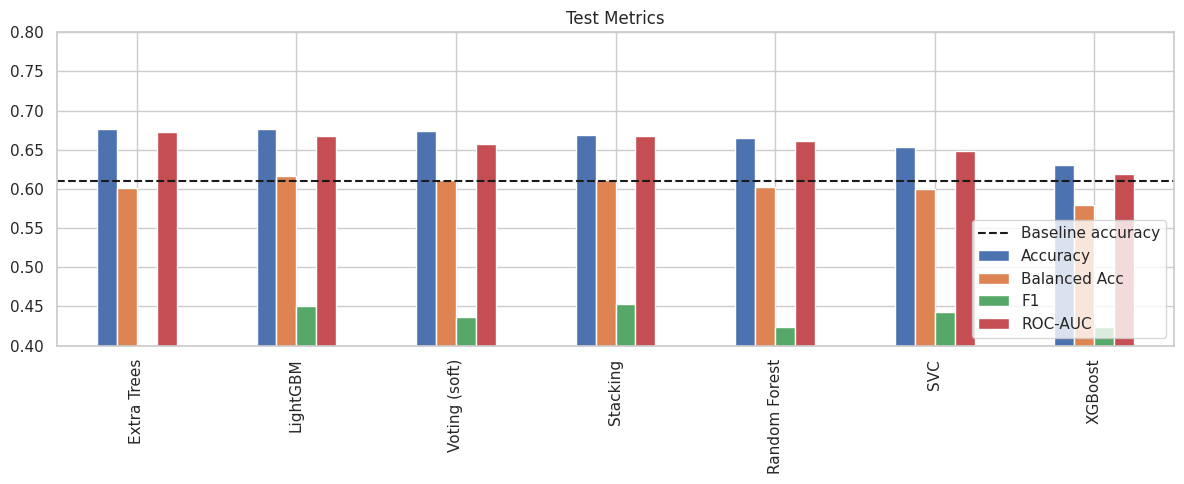

In [89]:
results[['Accuracy', 'Balanced Acc', 'F1', 'ROC-AUC']].plot.bar(figsize=(12, 5))
plt.axhline(1 - y_test.mean(), color='k', linestyle='--', label='Baseline accuracy')
plt.ylim(0.4, 0.8); plt.legend(loc='lower right'); plt.title('Test Metrics'); plt.tight_layout(); plt.show()

Best model: Extra Trees

                 precision    recall  f1-score   support

Not Potable (0)       0.67      0.94      0.78       400
    Potable (1)       0.75      0.26      0.38       256

       accuracy                           0.68       656
      macro avg       0.71      0.60      0.58       656
   weighted avg       0.70      0.68      0.63       656



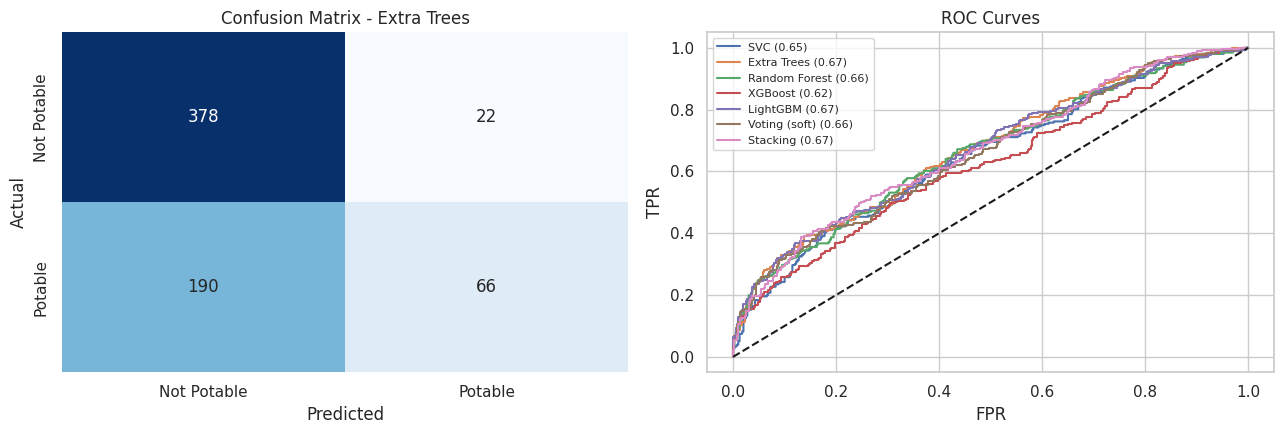

In [92]:
best_name = results.index[0]
best_model = final_models[best_name]
pred = best_model.predict(x_test)
print(f'Best model: {best_name}\n')
print(classification_report(y_test, pred, target_names=['Not Potable (0)', 'Potable (1)']))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=['Not Potable', 'Potable'], yticklabels=['Not Potable', 'Potable'])
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual'); axes[0].set_title(f'Confusion Matrix - {best_name}')
for n, m in final_models.items():
    fpr, tpr, _ = roc_curve(y_test, m.predict_proba(X_test)[:, 1])
    axes[1].plot(fpr, tpr, label=f"{n} ({roc_auc_score(y_test, m.predict_proba(X_test)[:, 1]):.2f})")
axes[1].plot([0, 1], [0, 1], 'k--'); axes[1].set_title('ROC Curves'); axes[1].legend(fontsize=8)
axes[1].set_xlabel('FPR'); axes[1].set_ylabel('TPR')
plt.tight_layout(); plt.show()

In [94]:
from imblearn.over_sampling import SMOTE
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from imblearn.pipeline import Pipeline as ImbPipeline

core = clone(tuned['Extra Trees'].named_steps['model'])
with_smote = ImbPipeline([
    ('imputer', KNNImputer(n_neighbors=5)), ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=RANDOM_STATE)), ('model', core)])
without_smote = make_pipe(clone(core))

cmp = {}
for label, p in [('Without SMOTE', without_smote), ('With SMOTE', with_smote)]:
    p.fit(x_train, y_train)
    pred = p.predict(x_test)
    cmp[label] = {'Accuracy': accuracy_score(y_test, pred), 'Recall (Potable)': recall_score(y_test, pred),
                  'Balanced Acc': balanced_accuracy_score(y_test, pred), 'F1': f1_score(y_test, pred)}
pd.DataFrame(cmp).T.round(4)

,Accuracy,Recall (Potable),Balanced Acc,F1
Without SMOTE,0.6768,0.2578,0.6014,0.3837
With SMOTE,0.6509,0.4297,0.6111,0.4900


# **Feature Importance**

In [96]:
from sklearn.inspection import permutation_importance

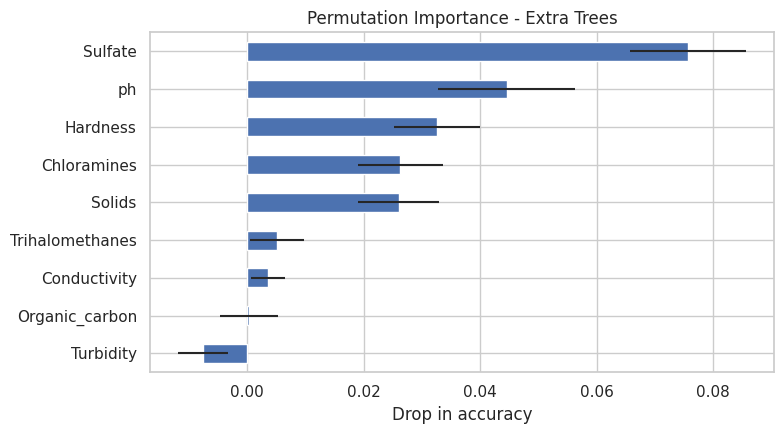

In [97]:
perm = permutation_importance(best_model, x_test, y_test, n_repeats=15, random_state=RANDOM_STATE,
                              scoring='accuracy', n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=X.columns).sort_values()
imp.plot.barh(figsize=(8, 4.5), xerr=pd.Series(perm.importances_std, index=X.columns)[imp.index])
plt.title(f'Permutation Importance - {best_name}'); plt.xlabel('Drop in accuracy'); plt.tight_layout(); plt.show()

قبل وبعد ال smoot

In [105]:
X_imp = StandardScaler().fit_transform(KNNImputer(n_neighbors=5).fit_transform(X))   # ❌ على الداتا كلها
Xb, yb = SMOTE(random_state=RANDOM_STATE).fit_resample(X_imp, y)                      # ❌ قبل الـ split
Xa, Xt, ya, yt = train_test_split(Xb, yb, test_size=0.2, random_state=RANDOM_STATE, stratify=yb)
leaky = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1).fit(Xa, ya)

correct = ImbPipeline([('imputer', KNNImputer(n_neighbors=5)), ('scaler', StandardScaler()),
                       ('smote', SMOTE(random_state=RANDOM_STATE)),
                       ('model', RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1))]
                      ).fit(x_train, y_train)

print(f"❌ SMOTE قبل الـ split (تسريب): {accuracy_score(yt, leaky.predict(Xt)):.4f}")
print(f"✅ SMOTE داخل الـ Pipeline (سليم): {accuracy_score(y_test, correct.predict(x_test)):.4f}")

❌ SMOTE قبل الـ split (تسريب): 0.7312
✅ SMOTE داخل الـ Pipeline (سليم): 0.6433


# **Save Model + Predict**

In [102]:
# import joblib
# from joblib import dump, load

In [104]:
# joblib.dump(best_model, 'best_water_model.joblib')

# loaded = joblib.load('best_water_model.joblib')
# sample = x_test.iloc[[0]]          # الـ Pipeline بيتعامل مع NaN والـ scaling لوحده
# print('Prediction:', 'Potable' if loaded.predict(sample)[0] == 1 else 'Not Potable',
#       '| Prob(Potable) =', round(loaded.predict_proba(sample)[0, 1], 3))

Prediction: Not Potable | Prob(Potable) = 0.304


In [107]:
import joblib

# حفظ أفضل موديل (الـ Pipeline أو الـ Voting المجمع) في ملف pkl
joblib.dump(best_model, 'water_potability_pipeline.pkl')
print("✅ تم حفظ الموديل بنجاح باسم: water_potability_pipeline.pkl")

✅ تم حفظ الموديل بنجاح باسم: water_potability_pipeline.pkl


In [109]:
import gradio as gr
import joblib
import pandas as pd

model = joblib.load('water_potability_pipeline.pkl')

def predict_water_potability(ph, Hardness, Solids, Chloramines, Sulfate, Conductivity, Organic_carbon, Trihalomethanes, Turbidity):
    input_data = pd.DataFrame([[ph, Hardness, Solids, Chloramines, Sulfate, Conductivity, Organic_carbon, Trihalomethanes, Turbidity]],
                              columns=['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate', 'Conductivity', 'Organic_carbon', 'Trihalomethanes', 'Turbidity'])

    prediction = model.predict(input_data)[0]
    probability = model.predict_proba(input_data)[0][1]

    if prediction == 1:
        return f" (Potable) - نسبة : {probability * 100:.2f}%"
    else:
        return f" (Not Potable) - نسبة : {(1 - probability) * 100:.2f}%"

demo = gr.Interface(
    fn=predict_water_potability,
    inputs=[
        gr.Number(label="pH (حموضة المياه)", value=7.0),
        gr.Number(label="Hardness (الصلابة)", value=200.0),
        gr.Number(label="Solids (المواد الصلبة الذائبة)", value=20000.0),
        gr.Number(label="Chloramines (الكلورامين)", value=7.0),
        gr.Number(label="Sulfate (الكبريتات)", value=330.0),
        gr.Number(label="Conductivity (التوصيل الكهربائي)", value=400.0),
        gr.Number(label="Organic_carbon (الكربون العضوي)", value=14.0),
        gr.Number(label="Trihalomethanes (الهالوميثانات الثلاثية)", value=60.0),
        gr.Number(label="Turbidity (التعكر)", value=4.0),
    ],
    outputs=gr.Textbox(label="نتيجة التقييم الفوري"),
    title="💧 Water Potability Prediction System",
    description="أدخل الخصائص الكيميائية والفيزيائية لعينة المياه لمعرفة ما إذا كانت صالحة للشرب باستخدام أفضل نموذج ذكاء اصطناعي مدرب."
)

if __name__ == "__main__":
    demo.launch()

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://75c0d5c5430b389233.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
